
# E5 — Conformal Prediction + Selective Abstention under LOSO Population Shift

## Scientific objective

E4 showed that discrimination transports reasonably well, while a decision threshold learned on source populations does not transfer uniformly to an unseen `Student_Type`.

E5 asks:

> **Can conformal prediction expose uncertainty and support selective abstention when a decision policy is transported to an unseen population?**

## Primary methods

1. **Marginal split conformal**
   - one nonconformity threshold \(q\) for both classes.

2. **Mondrian / class-conditional conformal**
   - separate thresholds \(q_0\) and \(q_1\) for low- and high-stress labels.

The base predictor is the same **group-blind ERM Logistic Regression** retained from E1–E4.

## LOSO protocol

For each held-out `Student_Type` and each repeat:

- the two source populations are divided into:
  - **proper training set**: 60%
  - **conformal calibration set**: 20%
  - **source check set**: 20%
- the model is fitted only on proper training data;
- conformal thresholds are estimated only from the calibration split;
- the same fitted model and thresholds are evaluated on:
  - the source check set (**in-domain reference**),
  - the held-out population (**population-shift target**).

This allows a direct test of whether nominal conformal coverage transports from source to unseen population.

## Nominal coverage levels

\[
1-\alpha \in \{0.90,\;0.95\}
\]

## Selective abstention rule

- singleton prediction set, e.g. `{High}` or `{Low}` → **make a decision**;
- ambiguous set `{Low, High}` → **abstain**;
- empty set → **abstain**.

The conformal prediction set is therefore also used as an uncertainty-aware decision policy.

## Metrics

### Set-valued reliability
- marginal coverage,
- low-stress coverage,
- high-stress coverage,
- coverage gap,
- average set size,
- singleton rate,
- ambiguity rate,
- empty-set rate.

### Selective prediction
- decision coverage,
- selective accuracy,
- selective risk,
- actionable high-stress recall,
- high-stress abstention rate,
- false-negative singleton rate.

> Split-conformal finite-sample coverage requires exchangeability between calibration and test observations. LOSO deliberately violates that assumption at the population level, so target-domain undercoverage is a scientific result rather than a software failure.


In [1]:

from pathlib import Path
import platform, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42
TARGET = "Stress_Level"
GROUP = "Student_Type"

N_REPEATS = 5
ALPHAS = [0.10, 0.05]  # nominal 90%, 95%
TRAIN_FRAC = 0.60
CAL_FRAC = 0.20
CHECK_FRAC = 0.20

DATA_CANDIDATES = [
    Path("/mnt/data/student-lifestyle-and-stress-dataset.csv"),
    Path("../data/student-lifestyle-and-stress-dataset.csv"),
    Path("student-lifestyle-and-stress-dataset.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Edit DATA_PATH.")

RESULT_DIR = Path("../outputs/E5")
RESULT_DIR.mkdir(exist_ok=True)

print("Python :", platform.python_version())
print("pandas :", pd.__version__)
print("sklearn:", sklearn.__version__)
print("Dataset:", DATA_PATH.resolve())
print("Repeats:", N_REPEATS)
print("Nominal coverage:", [1-a for a in ALPHAS])


Python : 3.13.5
pandas : 2.2.3
sklearn: 1.8.0
Dataset: /mnt/data/student-lifestyle-and-stress-dataset.csv
Repeats: 5
Nominal coverage: [0.9, 0.95]


In [2]:

df = pd.read_csv(DATA_PATH)

NUMERIC_FEATURES = [
    "Sleep_Hours",
    "Study_Hours",
    "Social_Media_Hours",
    "Attendance",
    "Exam_Pressure",
    "Family_Support",
]
CATEGORICAL_FEATURES = ["Month"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

e5_df = (
    df[df[GROUP].notna()]
    .copy()
    .reset_index(drop=False)
    .rename(columns={"index": "original_row_id"})
)
groups = sorted(e5_df[GROUP].unique().tolist())

print("Full dataset:", df.shape)
print("E5 rows:", len(e5_df))
print("Excluded missing Student_Type:", int(df[GROUP].isna().sum()))
print("Groups:", groups)


Full dataset: (25500, 9)
E5 rows: 24248
Excluded missing Student_Type: 1252
Groups: ['college', 'school', 'working_student']


# Base predictor

In [3]:

def make_lr_pipeline():
    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUMERIC_FEATURES),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL_FEATURES),
    ], sparse_threshold=0)

    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=SEED,
        )),
    ])



# Split-conformal construction

For a binary probabilistic classifier with \(p_1=P(Y=1|X)\) and \(p_0=1-p_1\), the nonconformity score for the observed label is:

\[
s_i = 1-p_{y_i}(x_i)
\]

For calibration scores \(s_1,\ldots,s_n\), the split-conformal threshold is the finite-sample order statistic:

\[
q_\alpha = s_{(k)}, \qquad
k=\left\lceil(n+1)(1-\alpha)\right\rceil
\]

with \(k\) capped at \(n\).

A candidate class \(c\) is included when:

\[
1-p_c(x)\le q_\alpha
\]

For Mondrian conformal, the same calculation is performed separately within each true calibration class.


In [4]:

def true_label_scores(y_true, p1):
    y = np.asarray(y_true).astype(int)
    p1 = np.asarray(p1, dtype=float)
    p_true = np.where(y == 1, p1, 1 - p1)
    return 1 - p_true

def conformal_qhat(scores, alpha):
    scores = np.sort(np.asarray(scores, dtype=float))
    n = len(scores)
    if n == 0:
        return np.nan
    k = int(np.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)
    return float(scores[k - 1])

def fit_conformal_thresholds(y_cal, p_cal, alpha, method):
    y = np.asarray(y_cal).astype(int)
    scores = true_label_scores(y, p_cal)

    if method == "marginal":
        q = conformal_qhat(scores, alpha)
        return {0: q, 1: q}

    if method == "mondrian":
        return {
            0: conformal_qhat(scores[y == 0], alpha),
            1: conformal_qhat(scores[y == 1], alpha),
        }

    raise ValueError("method must be 'marginal' or 'mondrian'")

def conformal_sets(p1, q_by_class):
    p1 = np.asarray(p1, dtype=float)
    p0 = 1 - p1

    include0 = (1 - p0) <= q_by_class[0]  # equivalently p1 <= q0
    include1 = (1 - p1) <= q_by_class[1]

    return include0.astype(int), include1.astype(int)

METHODS = ["marginal", "mondrian"]


# Evaluation metrics

In [5]:

def set_metrics(y_true, include0, include1):
    y = np.asarray(y_true).astype(int)
    i0 = np.asarray(include0).astype(bool)
    i1 = np.asarray(include1).astype(bool)

    set_size = i0.astype(int) + i1.astype(int)
    covered = np.where(y == 0, i0, i1)

    mask0 = y == 0
    mask1 = y == 1

    cov0 = covered[mask0].mean() if mask0.any() else np.nan
    cov1 = covered[mask1].mean() if mask1.any() else np.nan

    singleton = set_size == 1
    ambiguous = set_size == 2
    empty = set_size == 0

    # singleton label
    singleton_pred = np.full(len(y), -1, dtype=int)
    singleton_pred[singleton & i0] = 0
    singleton_pred[singleton & i1] = 1

    decided = singleton
    if decided.any():
        selective_accuracy = (
            singleton_pred[decided] == y[decided]
        ).mean()
        selective_risk = 1 - selective_accuracy
    else:
        selective_accuracy = np.nan
        selective_risk = np.nan

    true_pos = mask1
    actionable_high_recall = (
        ((singleton_pred == 1) & true_pos).sum() / true_pos.sum()
        if true_pos.sum() else np.nan
    )
    high_abstention = (
        ((ambiguous | empty) & true_pos).sum() / true_pos.sum()
        if true_pos.sum() else np.nan
    )
    false_negative_singleton_rate = (
        ((singleton_pred == 0) & true_pos).sum() / true_pos.sum()
        if true_pos.sum() else np.nan
    )

    return {
        "marginal_coverage": covered.mean(),
        "coverage_low": cov0,
        "coverage_high": cov1,
        "coverage_gap_abs": abs(cov0 - cov1),
        "avg_set_size": set_size.mean(),
        "singleton_rate": singleton.mean(),
        "ambiguity_rate": ambiguous.mean(),
        "empty_rate": empty.mean(),
        "decision_coverage": decided.mean(),
        "selective_accuracy": selective_accuracy,
        "selective_risk": selective_risk,
        "actionable_high_stress_recall": actionable_high_recall,
        "high_stress_abstention_rate": high_abstention,
        "false_negative_singleton_rate": false_negative_singleton_rate,
    }

SET_METRICS = [
    "marginal_coverage", "coverage_low", "coverage_high",
    "coverage_gap_abs", "avg_set_size", "singleton_rate",
    "ambiguity_rate", "empty_rate", "decision_coverage",
    "selective_accuracy", "selective_risk",
    "actionable_high_stress_recall",
    "high_stress_abstention_rate",
    "false_negative_singleton_rate",
]



# Source split helper

The split is stratified jointly by `Student_Type × target` to preserve both source domains and both classes across proper-train, calibration, and source-check partitions.


In [6]:

def joint_strata(frame):
    return (
        frame[GROUP].astype(str)
        + "__Y" + frame[TARGET].astype(int).astype(str)
    )

def source_three_way_split(source_df, seed):
    # First: 60% proper train, 40% temporary.
    train_df, temp_df = train_test_split(
        source_df,
        test_size=(CAL_FRAC + CHECK_FRAC),
        random_state=seed,
        stratify=joint_strata(source_df),
    )

    # Second: split temporary equally into calibration and source-check.
    relative_check = CHECK_FRAC / (CAL_FRAC + CHECK_FRAC)
    cal_df, check_df = train_test_split(
        temp_df,
        test_size=relative_check,
        random_state=seed + 1000,
        stratify=joint_strata(temp_df),
    )

    return (
        train_df.copy(),
        cal_df.copy(),
        check_df.copy(),
    )


# E5 LOSO experiment

In [7]:

metric_rows = []
threshold_rows = []
prediction_rows = []
base_discrimination_rows = []

for heldout in groups:
    source_df = e5_df[e5_df[GROUP] != heldout].copy()
    target_df = e5_df[e5_df[GROUP] == heldout].copy()

    for repeat in range(1, N_REPEATS + 1):
        seed = SEED + repeat * 101

        proper_train, cal_df, source_check = source_three_way_split(
            source_df, seed
        )

        model = make_lr_pipeline()
        model.fit(
            proper_train[FEATURES],
            proper_train[TARGET].astype(int),
        )

        p_cal = model.predict_proba(cal_df[FEATURES])[:, 1]
        p_source = model.predict_proba(source_check[FEATURES])[:, 1]
        p_target = model.predict_proba(target_df[FEATURES])[:, 1]

        # Context: discrimination only.
        for domain_name, part, prob in [
            ("source_check", source_check, p_source),
            ("target_loso", target_df, p_target),
        ]:
            y_dom = part[TARGET].astype(int).to_numpy()
            base_discrimination_rows.append({
                "heldout_group": heldout,
                "repeat": repeat,
                "domain": domain_name,
                "n": len(part),
                "prevalence": y_dom.mean(),
                "roc_auc": roc_auc_score(y_dom, prob),
                "pr_auc": average_precision_score(y_dom, prob),
            })

        for alpha in ALPHAS:
            nominal = 1 - alpha

            for method in METHODS:
                q_by_class = fit_conformal_thresholds(
                    cal_df[TARGET].astype(int).to_numpy(),
                    p_cal,
                    alpha=alpha,
                    method=method,
                )

                threshold_rows.append({
                    "heldout_group": heldout,
                    "repeat": repeat,
                    "method": method,
                    "alpha": alpha,
                    "nominal_coverage": nominal,
                    "n_cal": len(cal_df),
                    "n_cal_low": int((cal_df[TARGET] == 0).sum()),
                    "n_cal_high": int((cal_df[TARGET] == 1).sum()),
                    "q_low": q_by_class[0],
                    "q_high": q_by_class[1],
                })

                for domain_name, part, prob in [
                    ("source_check", source_check, p_source),
                    ("target_loso", target_df, p_target),
                ]:
                    y_dom = part[TARGET].astype(int).to_numpy()
                    i0, i1 = conformal_sets(prob, q_by_class)

                    metrics = set_metrics(y_dom, i0, i1)
                    metric_rows.append({
                        "heldout_group": heldout,
                        "repeat": repeat,
                        "domain": domain_name,
                        "method": method,
                        "alpha": alpha,
                        "nominal_coverage": nominal,
                        "n": len(part),
                        "prevalence": y_dom.mean(),
                        **metrics,
                    })

                    # Row-level target predictions are useful for later E6.
                    if domain_name == "target_loso":
                        for rid, yt, pr, a0, a1 in zip(
                            part["original_row_id"].to_numpy(),
                            y_dom,
                            prob,
                            i0,
                            i1,
                        ):
                            prediction_rows.append({
                                "original_row_id": int(rid),
                                "heldout_group": heldout,
                                "repeat": repeat,
                                "method": method,
                                "alpha": alpha,
                                "y_true": int(yt),
                                "prob_high": float(pr),
                                "include_low": int(a0),
                                "include_high": int(a1),
                                "set_size": int(a0) + int(a1),
                            })

metrics = pd.DataFrame(metric_rows)
thresholds = pd.DataFrame(threshold_rows)
predictions = pd.DataFrame(prediction_rows)
base_disc = pd.DataFrame(base_discrimination_rows)

metrics.to_csv(
    RESULT_DIR / "e5_conformal_metrics_by_repeat.csv",
    index=False
)
thresholds.to_csv(
    RESULT_DIR / "e5_conformal_thresholds.csv",
    index=False
)
predictions.to_csv(
    RESULT_DIR / "e5_target_conformal_predictions.csv",
    index=False
)
base_disc.to_csv(
    RESULT_DIR / "e5_base_discrimination.csv",
    index=False
)

display(metrics.head())


,heldout_group,repeat,domain,method,alpha,nominal_coverage,n,prevalence,marginal_coverage,coverage_low,coverage_high,coverage_gap_abs,avg_set_size,singleton_rate,ambiguity_rate,empty_rate,decision_coverage,selective_accuracy,selective_risk,actionable_high_stress_recall,high_stress_abstention_rate,false_negative_singleton_rate
0,college,1,source_check,marginal,0.10,0.90,2172,0.283610,0.905157,0.976864,0.724026,0.252838,1.187845,0.812155,0.187845,0.0,0.812155,0.883220,0.116780,0.404221,0.319805,0.275974
1,college,1,target_loso,marginal,0.10,0.90,13391,0.312523,0.903443,0.963611,0.771087,0.192523,1.232171,0.767829,0.232171,0.0,0.767829,0.874246,0.125754,0.398566,0.372521,0.228913
2,college,1,source_check,mondrian,0.10,0.90,2172,0.283610,0.916206,0.924807,0.894481,0.030327,1.307551,0.692449,0.307551,0.0,0.692449,0.878989,0.121011,0.615260,0.279221,0.105519
3,college,1,target_loso,mondrian,0.10,0.90,13391,0.312523,0.900605,0.893548,0.916129,0.022581,1.325442,0.674558,0.325442,0.0,0.674558,0.852651,0.147349,0.618160,0.297969,0.083871
4,college,1,source_check,marginal,0.05,0.95,2172,0.283610,0.949816,0.992288,0.842532,0.149755,1.366022,0.633978,0.366022,0.0,0.633978,0.920842,0.079158,0.245130,0.597403,0.157468


# Mean LOSO results across repeats

In [8]:

summary = (
    metrics
    .groupby(
        ["heldout_group", "domain", "method", "alpha", "nominal_coverage"]
    )[SET_METRICS]
    .agg(["mean", "std"])
)
display(summary)
summary.to_csv(
    RESULT_DIR / "e5_summary_mean_sd.csv"
)


marginal_coverage  ... false_negative_singleton_rate
                                                                          mean  ...                           std
heldout_group   domain       method   alpha nominal_coverage                    ...                              
college         source_check marginal 0.05  0.95                      0.955709  ...                      0.017088
                                      0.10  0.90                      0.903867  ...                      0.031964
                             mondrian 0.05  0.95                      0.955617  ...                      0.009767
                                      0.10  0.90                      0.909300  ...                      0.008230
                target_loso  marginal 0.05  0.95                      0.956538  ...                      0.008969
                                      0.10  0.90                      0.900082  ...                      0.008929
                             mondrian 0.05  0.95                      0.948831  ...                      0.004948
                                      0.10  0.90                      0.899111  ...                      0.005696
school          source_check marginal 0.05  0.95                      0.950850  ...                      0.012308
                                      0.10  0.90                      0.897861  ...                      0.018502
                             mondrian 0.05  0.95                      0.948875  ...                      0.010729
                                      0.10  0.90                      0.900439  ...                      0.012269
                target_loso  marginal 0.05  0.95                      0.951935  ...                      0.014169
                                      0.10  0.90                      0.918120  ...                      0.015296
                             mondrian 0.05  0.95                      0.961966  ...                      0.015733
                                      0.10  0.90                      0.922206  ...                      0.013070
working_student source_check marginal 0.05  0.95                      0.952614  ...                      0.009824
                                      0.10  0.90                      0.902241  ...                      0.011157
                             mondrian 0.05  0.95                      0.952614  ...                      0.009493
                                      0.10  0.90                      0.905846  ...                      0.014110
                target_loso  marginal 0.05  0.95                      0.946030  ...                      0.003048
                                      0.10  0.90                      0.879363  ...                      0.008974
                             mondrian 0.05  0.95                      0.933706  ...                      0.004448
                                      0.10  0.90                      0.882465  ...                      0.003087

[24 rows x 28 columns]


# Coverage transportability

Define target coverage deterioration as:

\[
\Delta Coverage =
Coverage_{source-check} - Coverage_{target-LOSO}
\]

Positive values mean the conformal set covers the true label less often after population shift.


In [9]:

mean_metrics = (
    metrics
    .groupby(
        ["heldout_group", "domain", "method", "alpha", "nominal_coverage"],
        as_index=False
    )
    .agg(
        n=("n", "mean"),
        prevalence=("prevalence", "mean"),
        **{m: (m, "mean") for m in SET_METRICS},
    )
)

source_mean = mean_metrics[
    mean_metrics["domain"] == "source_check"
].drop(columns="domain")

target_mean = mean_metrics[
    mean_metrics["domain"] == "target_loso"
].drop(columns="domain")

transport = source_mean.merge(
    target_mean,
    on=["heldout_group", "method", "alpha", "nominal_coverage"],
    suffixes=("_source", "_target"),
)

for metric in [
    "marginal_coverage", "coverage_low", "coverage_high",
    "selective_accuracy", "decision_coverage",
]:
    transport[f"{metric}_transport_change"] = (
        transport[f"{metric}_source"] -
        transport[f"{metric}_target"]
    )

transport["target_undercoverage_vs_nominal"] = (
    transport["nominal_coverage"] -
    transport["marginal_coverage_target"]
)
transport["target_high_undercoverage_vs_nominal"] = (
    transport["nominal_coverage"] -
    transport["coverage_high_target"]
)

display(
    transport[
        [
            "heldout_group", "method", "nominal_coverage",
            "marginal_coverage_source", "marginal_coverage_target",
            "target_undercoverage_vs_nominal",
            "coverage_high_source", "coverage_high_target",
            "target_high_undercoverage_vs_nominal",
            "decision_coverage_target", "selective_accuracy_target",
            "actionable_high_stress_recall_target",
            "high_stress_abstention_rate_target",
        ]
    ].round(5)
)

transport.to_csv(
    RESULT_DIR / "e5_coverage_transportability.csv",
    index=False
)


,heldout_group,method,nominal_coverage,marginal_coverage_source,marginal_coverage_target,target_undercoverage_vs_nominal,coverage_high_source,coverage_high_target,target_high_undercoverage_vs_nominal,decision_coverage_target,selective_accuracy_target,actionable_high_stress_recall_target,high_stress_abstention_rate_target
0,college,marginal,0.95,0.95571,0.95654,-0.00654,0.86136,0.88492,0.06508,0.55064,0.92118,0.21945,0.66547
1,college,marginal,0.90,0.90387,0.90008,-0.00008,0.73571,0.76640,0.13360,0.77748,0.87153,0.41357,0.35283
2,college,mondrian,0.95,0.95562,0.94883,0.00117,0.95162,0.95924,-0.00924,0.47783,0.89298,0.48148,0.47775
3,college,mondrian,0.90,0.90930,0.89911,0.00089,0.90779,0.92339,-0.02339,0.66253,0.84789,0.62767,0.29572
4,school,marginal,0.95,0.95085,0.95193,-0.00193,0.88169,0.78654,0.16346,0.67490,0.92884,0.11598,0.67056
5,school,marginal,0.90,0.89786,0.91812,-0.01812,0.78393,0.66488,0.23512,0.83046,0.90145,0.27251,0.39238
6,school,mondrian,0.95,0.94888,0.96197,-0.01197,0.94764,0.88921,0.06079,0.56250,0.93244,0.29376,0.59546
7,school,mondrian,0.90,0.90044,0.92221,-0.02221,0.89843,0.81087,0.08913,0.74499,0.89557,0.44152,0.36934
8,working_student,marginal,0.95,0.95261,0.94603,0.00397,0.85577,0.89724,0.05276,0.55368,0.90255,0.34694,0.55030
9,working_student,marginal,0.90,0.90224,0.87936,0.02064,0.73684,0.79437,0.10563,0.78995,0.84730,0.52951,0.26486


# Weighted and worst-group target summary

In [10]:

target_only = mean_metrics[
    mean_metrics["domain"] == "target_loso"
].copy()

weighted_rows = []
for (method, alpha), part in target_only.groupby(["method", "alpha"]):
    w = part["n"] / part["n"].sum()
    nominal = float(part["nominal_coverage"].iloc[0])

    weighted_rows.append({
        "method": method,
        "alpha": alpha,
        "nominal_coverage": nominal,
        "weighted_marginal_coverage": np.sum(
            w * part["marginal_coverage"]
        ),
        "worst_group_marginal_coverage": part["marginal_coverage"].min(),
        "weighted_high_coverage": np.sum(
            w * part["coverage_high"]
        ),
        "worst_group_high_coverage": part["coverage_high"].min(),
        "weighted_avg_set_size": np.sum(
            w * part["avg_set_size"]
        ),
        "weighted_decision_coverage": np.sum(
            w * part["decision_coverage"]
        ),
        "worst_group_decision_coverage": part["decision_coverage"].min(),
        "weighted_selective_accuracy": np.sum(
            w * part["selective_accuracy"]
        ),
        "worst_group_selective_accuracy": part["selective_accuracy"].min(),
        "weighted_actionable_high_recall": np.sum(
            w * part["actionable_high_stress_recall"]
        ),
        "worst_group_actionable_high_recall": (
            part["actionable_high_stress_recall"].min()
        ),
        "weighted_high_abstention": np.sum(
            w * part["high_stress_abstention_rate"]
        ),
    })

weighted_summary = pd.DataFrame(weighted_rows)
display(weighted_summary.round(5))
weighted_summary.to_csv(
    RESULT_DIR / "e5_target_weighted_worst_summary.csv",
    index=False
)


,method,alpha,nominal_coverage,weighted_marginal_coverage,worst_group_marginal_coverage,weighted_high_coverage,worst_group_high_coverage,weighted_avg_set_size,weighted_decision_coverage,worst_group_decision_coverage,weighted_selective_accuracy,worst_group_selective_accuracy,weighted_actionable_high_recall,worst_group_actionable_high_recall,weighted_high_abstention
0,marginal,0.05,0.95,0.95330,0.94603,0.86295,0.78654,1.41790,0.58210,0.55064,0.91937,0.90255,0.21918,0.11598,0.64377
1,marginal,0.10,0.90,0.90043,0.87936,0.74677,0.66488,1.20688,0.79312,0.77748,0.87412,0.84730,0.40167,0.27251,0.34511
2,mondrian,0.05,0.95,0.94908,0.93371,0.94426,0.88921,1.49845,0.50155,0.47783,0.89723,0.86517,0.45492,0.29376,0.48934
3,mondrian,0.10,0.90,0.90153,0.88246,0.89842,0.81087,1.31373,0.68627,0.66253,0.85554,0.82686,0.59632,0.44152,0.30210


# Selective-abstention detail by unseen population

In [11]:

selective_table = target_only[
    [
        "heldout_group", "method", "nominal_coverage",
        "decision_coverage", "selective_accuracy", "selective_risk",
        "actionable_high_stress_recall",
        "high_stress_abstention_rate",
        "false_negative_singleton_rate",
        "avg_set_size", "ambiguity_rate", "empty_rate",
    ]
].sort_values(
    ["nominal_coverage", "heldout_group", "method"]
)

display(selective_table.round(5))
selective_table.to_csv(
    RESULT_DIR / "e5_selective_abstention_target.csv",
    index=False
)


,heldout_group,method,nominal_coverage,decision_coverage,selective_accuracy,selective_risk,actionable_high_stress_recall,high_stress_abstention_rate,false_negative_singleton_rate,avg_set_size,ambiguity_rate,empty_rate
5,college,marginal,0.90,0.77748,0.87153,0.12847,0.41357,0.35283,0.23360,1.22252,0.22252,0.0
7,college,mondrian,0.90,0.66253,0.84789,0.15211,0.62767,0.29572,0.07661,1.33747,0.33747,0.0
13,school,marginal,0.90,0.83046,0.90145,0.09855,0.27251,0.39238,0.33512,1.16954,0.16954,0.0
15,school,mondrian,0.90,0.74499,0.89557,0.10443,0.44152,0.36934,0.18913,1.25501,0.25501,0.0
21,working_student,marginal,0.90,0.78995,0.84730,0.15270,0.52951,0.26486,0.20563,1.21005,0.21005,0.0
23,working_student,mondrian,0.90,0.67887,0.82686,0.17314,0.70222,0.23606,0.06172,1.32113,0.32113,0.0
4,college,marginal,0.95,0.55064,0.92118,0.07882,0.21945,0.66547,0.11508,1.44936,0.44936,0.0
6,college,mondrian,0.95,0.47783,0.89298,0.10702,0.48148,0.47775,0.04076,1.52217,0.52217,0.0
12,school,marginal,0.95,0.67490,0.92884,0.07116,0.11598,0.67056,0.21346,1.32510,0.32510,0.0
14,school,mondrian,0.95,0.56250,0.93244,0.06756,0.29376,0.59546,0.11079,1.43750,0.43750,0.0


# Figures

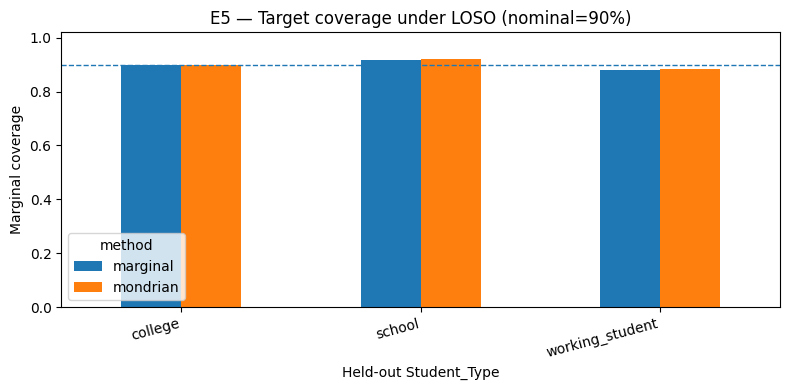

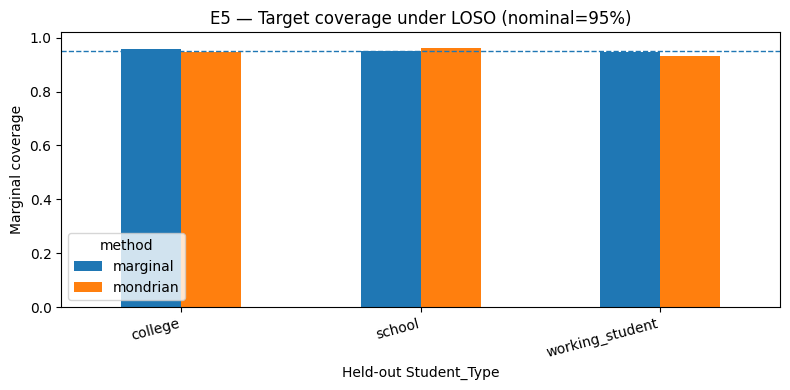

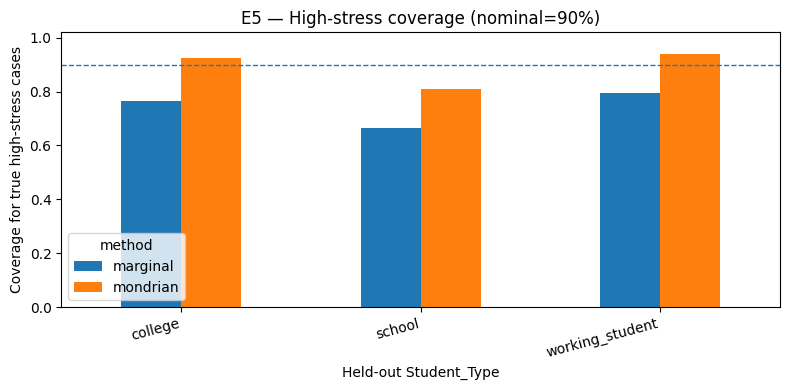

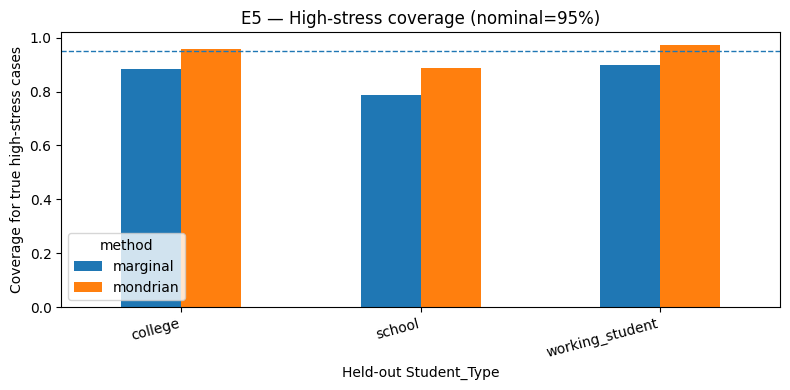

In [12]:

# 1. Target marginal coverage vs nominal
for nominal in sorted(target_only["nominal_coverage"].unique()):
    part = target_only[target_only["nominal_coverage"] == nominal]
    pivot = part.pivot(
        index="heldout_group",
        columns="method",
        values="marginal_coverage",
    )
    ax = pivot.plot(kind="bar", figsize=(8, 4))
    ax.axhline(nominal, linestyle="--", linewidth=1)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Marginal coverage")
    ax.set_xlabel("Held-out Student_Type")
    ax.set_title(
        f"E5 — Target coverage under LOSO (nominal={nominal:.0%})"
    )
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(
        RESULT_DIR / f"fig_e5_target_coverage_{int(nominal*100)}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()

# 2. High-stress class coverage
for nominal in sorted(target_only["nominal_coverage"].unique()):
    part = target_only[target_only["nominal_coverage"] == nominal]
    pivot = part.pivot(
        index="heldout_group",
        columns="method",
        values="coverage_high",
    )
    ax = pivot.plot(kind="bar", figsize=(8, 4))
    ax.axhline(nominal, linestyle="--", linewidth=1)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Coverage for true high-stress cases")
    ax.set_xlabel("Held-out Student_Type")
    ax.set_title(
        f"E5 — High-stress coverage (nominal={nominal:.0%})"
    )
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(
        RESULT_DIR / f"fig_e5_high_coverage_{int(nominal*100)}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()


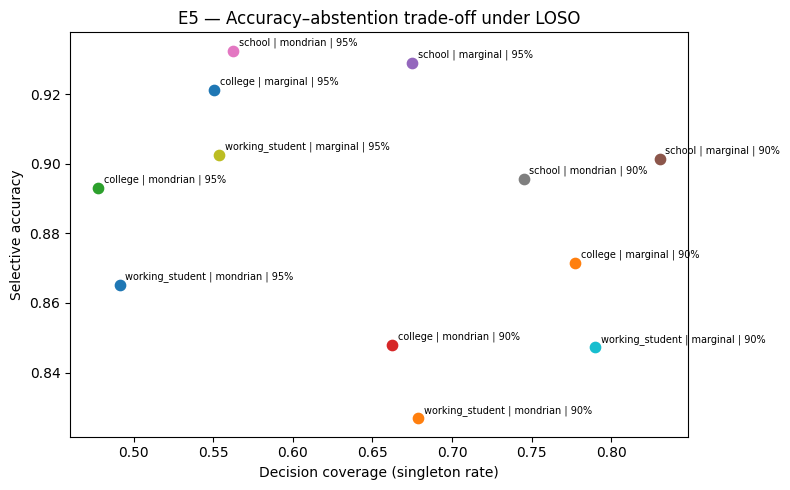

In [13]:

# 3. Decision coverage vs selective accuracy
fig, ax = plt.subplots(figsize=(8, 5))

for _, row in target_only.iterrows():
    label = (
        f"{row['heldout_group']} | "
        f"{row['method']} | "
        f"{row['nominal_coverage']:.0%}"
    )
    ax.scatter(
        row["decision_coverage"],
        row["selective_accuracy"],
        s=55,
    )
    ax.annotate(
        label,
        (row["decision_coverage"], row["selective_accuracy"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
    )

ax.set_xlabel("Decision coverage (singleton rate)")
ax.set_ylabel("Selective accuracy")
ax.set_title("E5 — Accuracy–abstention trade-off under LOSO")
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e5_selective_accuracy_vs_coverage.png",
    dpi=200, bbox_inches="tight"
)
plt.show()



# Optional target-label oracle diagnostic

The following diagnostic asks:

> If a small labeled sample from the target population were available solely for conformal recalibration, how much of the target undercoverage could be recovered?

This is **not** a zero-shot LOSO method and is never mixed with the primary results.

For each repeat:
- keep the source-trained classifier unchanged;
- split the held-out population 50/50;
- use one half only to recompute conformal thresholds;
- evaluate those thresholds on the other half.

This isolates **conformal-threshold transportability** from model transportability.


In [14]:

oracle_rows = []

for heldout in groups:
    source_df = e5_df[e5_df[GROUP] != heldout].copy()
    target_df = e5_df[e5_df[GROUP] == heldout].copy()

    for repeat in range(1, N_REPEATS + 1):
        seed = SEED + repeat * 101

        proper_train, cal_df, source_check = source_three_way_split(
            source_df, seed
        )

        model = make_lr_pipeline()
        model.fit(
            proper_train[FEATURES],
            proper_train[TARGET].astype(int),
        )

        # Target split used only for the oracle diagnostic.
        target_cal, target_eval = train_test_split(
            target_df,
            test_size=0.50,
            random_state=seed + 5000,
            stratify=target_df[TARGET],
        )

        p_tcal = model.predict_proba(target_cal[FEATURES])[:, 1]
        p_teval = model.predict_proba(target_eval[FEATURES])[:, 1]

        for alpha in ALPHAS:
            for method in METHODS:
                q_oracle = fit_conformal_thresholds(
                    target_cal[TARGET].astype(int).to_numpy(),
                    p_tcal,
                    alpha,
                    method,
                )
                i0, i1 = conformal_sets(p_teval, q_oracle)

                oracle_rows.append({
                    "heldout_group": heldout,
                    "repeat": repeat,
                    "method": method,
                    "alpha": alpha,
                    "nominal_coverage": 1-alpha,
                    "diagnostic": "target_label_oracle_recalibration",
                    "n_target_cal": len(target_cal),
                    "n_target_eval": len(target_eval),
                    **set_metrics(
                        target_eval[TARGET].astype(int).to_numpy(),
                        i0, i1
                    ),
                })

oracle = pd.DataFrame(oracle_rows)
oracle_summary = (
    oracle
    .groupby(
        ["heldout_group", "method", "alpha", "nominal_coverage"]
    )[SET_METRICS]
    .agg(["mean", "std"])
)

display(oracle_summary)
oracle.to_csv(
    RESULT_DIR / "e5_oracle_target_recalibration_by_repeat.csv",
    index=False
)
oracle_summary.to_csv(
    RESULT_DIR / "e5_oracle_target_recalibration_summary.csv"
)


marginal_coverage  ... false_negative_singleton_rate
                                                             mean  ...                           std
heldout_group   method   alpha nominal_coverage                    ...                              
college         marginal 0.05  0.95                      0.950179  ...                      0.006968
                         0.10  0.90                      0.902599  ...                      0.010654
                mondrian 0.05  0.95                      0.951434  ...                      0.006520
                         0.10  0.90                      0.898088  ...                      0.006113
school          marginal 0.05  0.95                      0.950847  ...                      0.031896
                         0.10  0.90                      0.898638  ...                      0.027519
                mondrian 0.05  0.95                      0.951046  ...                      0.017060
                         0.10  0.90                      0.902358  ...                      0.027743
working_student marginal 0.05  0.95                      0.946485  ...                      0.016545
                         0.10  0.90                      0.898015  ...                      0.010698
                mondrian 0.05  0.95                      0.947891  ...                      0.013631
                         0.10  0.90                      0.895037  ...                      0.019481

[12 rows x 28 columns]


# Interpretation logic

## Result pattern A — source coverage near nominal, target coverage below nominal

This is direct evidence that **split-conformal coverage does not transport under population shift**, consistent with the failure of exchangeability.

## Result pattern B — Mondrian improves high-stress coverage

Then class imbalance / asymmetric score behavior is an important part of the uncertainty problem.

However, class-conditional coverage on source data still does not guarantee target-population coverage under shift.

## Result pattern C — singleton decisions are highly accurate but sparse

This supports **selective abstention**:
the system becomes more reliable by refusing ambiguous cases, at the cost of intervention/decision coverage.

## Result pattern D — actionable high-stress recall becomes low

Then conformal abstention is safe in a statistical sense but may be operationally inadequate for screening. This trade-off must be made explicit.

## Oracle interpretation

If target-label recalibration restores nominal coverage while the source-calibrated conformal method undercovers, the dominant failure is **conformal threshold transportability** rather than the ranking model itself.

## Claims to avoid

Do not claim:
- guaranteed target coverage under LOSO,
- clinical safety,
- causal inference,
- formal fairness guarantees.

The correct claim is empirical:
**uncertainty guarantees derived under source exchangeability can degrade under unseen population shift.**


In [15]:

manifest = {
    "experiment": "E5 Conformal Prediction + Selective Abstention under LOSO",
    "dataset_rows_known_group": int(len(e5_df)),
    "excluded_missing_group": int(df[GROUP].isna().sum()),
    "base_model": "group-blind ERM Logistic Regression",
    "features": FEATURES,
    "groups": groups,
    "methods": METHODS,
    "alphas": ALPHAS,
    "nominal_coverages": [1-a for a in ALPHAS],
    "n_repeats": N_REPEATS,
    "source_split": {
        "proper_train": TRAIN_FRAC,
        "calibration": CAL_FRAC,
        "source_check": CHECK_FRAC,
    },
    "selective_rule": "decide only for singleton conformal prediction sets",
    "oracle": "target-label conformal recalibration diagnostic; non-deployable",
    "seed": SEED,
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
}

with open(
    RESULT_DIR / "run_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2)

print("Saved outputs:")
for p in sorted(RESULT_DIR.glob("*")):
    print("-", p)


Saved outputs:
- student_stress_e5_outputs/e5_base_discrimination.csv
- student_stress_e5_outputs/e5_conformal_metrics_by_repeat.csv
- student_stress_e5_outputs/e5_conformal_thresholds.csv
- student_stress_e5_outputs/e5_coverage_transportability.csv
- student_stress_e5_outputs/e5_oracle_target_recalibration_by_repeat.csv
- student_stress_e5_outputs/e5_oracle_target_recalibration_summary.csv
- student_stress_e5_outputs/e5_selective_abstention_target.csv
- student_stress_e5_outputs/e5_summary_mean_sd.csv
- student_stress_e5_outputs/e5_target_conformal_predictions.csv
- student_stress_e5_outputs/e5_target_weighted_worst_summary.csv
- student_stress_e5_outputs/fig_e5_high_coverage_90.png
- student_stress_e5_outputs/fig_e5_high_coverage_95.png
- student_stress_e5_outputs/fig_e5_selective_accuracy_vs_coverage.png
- student_stress_e5_outputs/fig_e5_target_coverage_90.png
- student_stress_e5_outputs/fig_e5_target_coverage_95.png
- student_stress_e5_outputs/run_manifest.json
